In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [3]:
train = pd.read_csv("dataset/train.csv")
test = pd.read_csv("dataset/test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)
train.head()

Train shape: (614, 13)
Test shape: (367, 12)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [4]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 62.5 KB


In [5]:
missing = train.isnull().sum()
missing_pct = (missing / len(train) * 100).round(1)
pd.DataFrame({"Missing": missing, "Percent": missing_pct}).sort_values("Missing", ascending=False)

,Missing,Percent
Credit_History,50,8.1
Self_Employed,32,5.2
LoanAmount,22,3.6
Dependents,15,2.4
Loan_Amount_Term,14,2.3
Gender,13,2.1
Married,3,0.5
Education,0,0.0
Loan_ID,0,0.0
CoapplicantIncome,0,0.0


In [6]:
train.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [7]:
cat_cols = ["Gender", "Married", "Dependents", "Education",
            "Self_Employed", "Property_Area", "Credit_History", "Loan_Status"]

for col in cat_cols:
    print(train[col].value_counts(dropna=False), "\n")

Gender
Male      489
Female    112
NaN        13
Name: count, dtype: int64 

Married
Yes    398
No     213
NaN      3
Name: count, dtype: int64 

Dependents
0      345
1      102
2      101
3+      51
NaN     15
Name: count, dtype: int64 

Education
Graduate        480
Not Graduate    134
Name: count, dtype: int64 

Self_Employed
No     500
Yes     82
NaN     32
Name: count, dtype: int64 

Property_Area
Semiurban    233
Urban        202
Rural        179
Name: count, dtype: int64 

Credit_History
1.0    475
0.0     89
NaN     50
Name: count, dtype: int64 

Loan_Status
Y    422
N    192
Name: count, dtype: int64 



In [8]:
print("Duplicate rows:", train.duplicated().sum())
print("Duplicate Loan IDs:", train["Loan_ID"].duplicated().sum())

Duplicate rows: 0
Duplicate Loan IDs: 0


## DATA CLEANING

In [9]:
df = train.copy()

df["Dependents"] = df["Dependents"].replace("3+", "3")
print(df["Dependents"].value_counts(dropna=False))

Dependents
0      345
1      102
2      101
3       51
NaN     15
Name: count, dtype: int64


In [10]:
credit_check = df["Credit_History"].fillna("Missing")
pd.crosstab(credit_check, df["Loan_Status"], normalize="index").round(3) * 100

Loan_Status,N,Y
Credit_History,,
0.0,92.1,7.9
1.0,20.4,79.6
Missing,26.0,74.0


In [11]:
# Text columns: fill with the most common value (mode)
for col in ["Gender", "Married", "Dependents", "Self_Employed"]:
    df[col] = df[col].fillna(df[col].mode()[0])

# Credit_History: fill with 1, based on the approval-rate check above
df["Credit_History"] = df["Credit_History"].fillna(1)

# LoanAmount: fill with the median, because the column is skewed
df["LoanAmount"] = df["LoanAmount"].fillna(df["LoanAmount"].median())

# Loan_Amount_Term: fill with the most common term (360)
df["Loan_Amount_Term"] = df["Loan_Amount_Term"].fillna(df["Loan_Amount_Term"].mode()[0])

df.isnull().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

In [12]:
df["Dependents"] = df["Dependents"].astype(int)
df["Credit_History"] = df["Credit_History"].astype(int)
df["Loan_Amount_Term"] = df["Loan_Amount_Term"].astype(int)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             614 non-null    str    
 2   Married            614 non-null    str    
 3   Dependents         614 non-null    int64  
 4   Education          614 non-null    str    
 5   Self_Employed      614 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         614 non-null    float64
 9   Loan_Amount_Term   614 non-null    int64  
 10  Credit_History     614 non-null    int64  
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(2), int64(4), str(7)
memory usage: 62.5 KB


In [13]:
def count_outliers(col):
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    return ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()

for col in ["ApplicantIncome", "CoapplicantIncome", "LoanAmount"]:
    print(col, count_outliers(col))

ApplicantIncome 50
CoapplicantIncome 18
LoanAmount 41


In [14]:
# Household income: many applicants rely on a co-applicant's income
df["TotalIncome"] = df["ApplicantIncome"] + df["CoapplicantIncome"]

# How big is the loan compared with income? (LoanAmount is in thousands)
df["LoanToIncome"] = (df["LoanAmount"] * 1000 / df["TotalIncome"]).round(1)

# 1 = approved, 0 = rejected, so the average gives the approval rate
df["Approved"] = (df["Loan_Status"] == "Y").astype(int)

df[["ApplicantIncome", "CoapplicantIncome", "TotalIncome",
    "LoanAmount", "LoanToIncome", "Loan_Status", "Approved"]].head()

,ApplicantIncome,CoapplicantIncome,TotalIncome,LoanAmount,LoanToIncome,Loan_Status,Approved
0,5849,0.0,5849.0,128.0,21.9,Y,1
1,4583,1508.0,6091.0,128.0,21.0,N,0
2,3000,0.0,3000.0,66.0,22.0,Y,1
3,2583,2358.0,4941.0,120.0,24.3,Y,1
4,6000,0.0,6000.0,141.0,23.5,Y,1


## EXPLORATORY DATA ANALYSIS

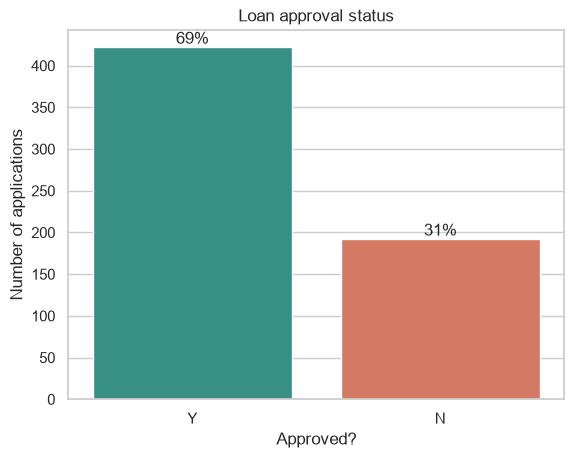

In [15]:
import os
os.makedirs("images", exist_ok=True)

ax = sns.countplot(data=df, x="Loan_Status", order=["Y", "N"],
                   hue="Loan_Status", palette={"Y": "#2a9d8f", "N": "#e76f51"}, legend=False)

for p in ax.patches:
    pct = p.get_height() / len(df) * 100
    ax.annotate(f"{pct:.0f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")

ax.set_title("Loan approval status")
ax.set_xlabel("Approved?")
ax.set_ylabel("Number of applications")
plt.savefig("images/01_loan_status.png", dpi=150, bbox_inches="tight")
plt.show()

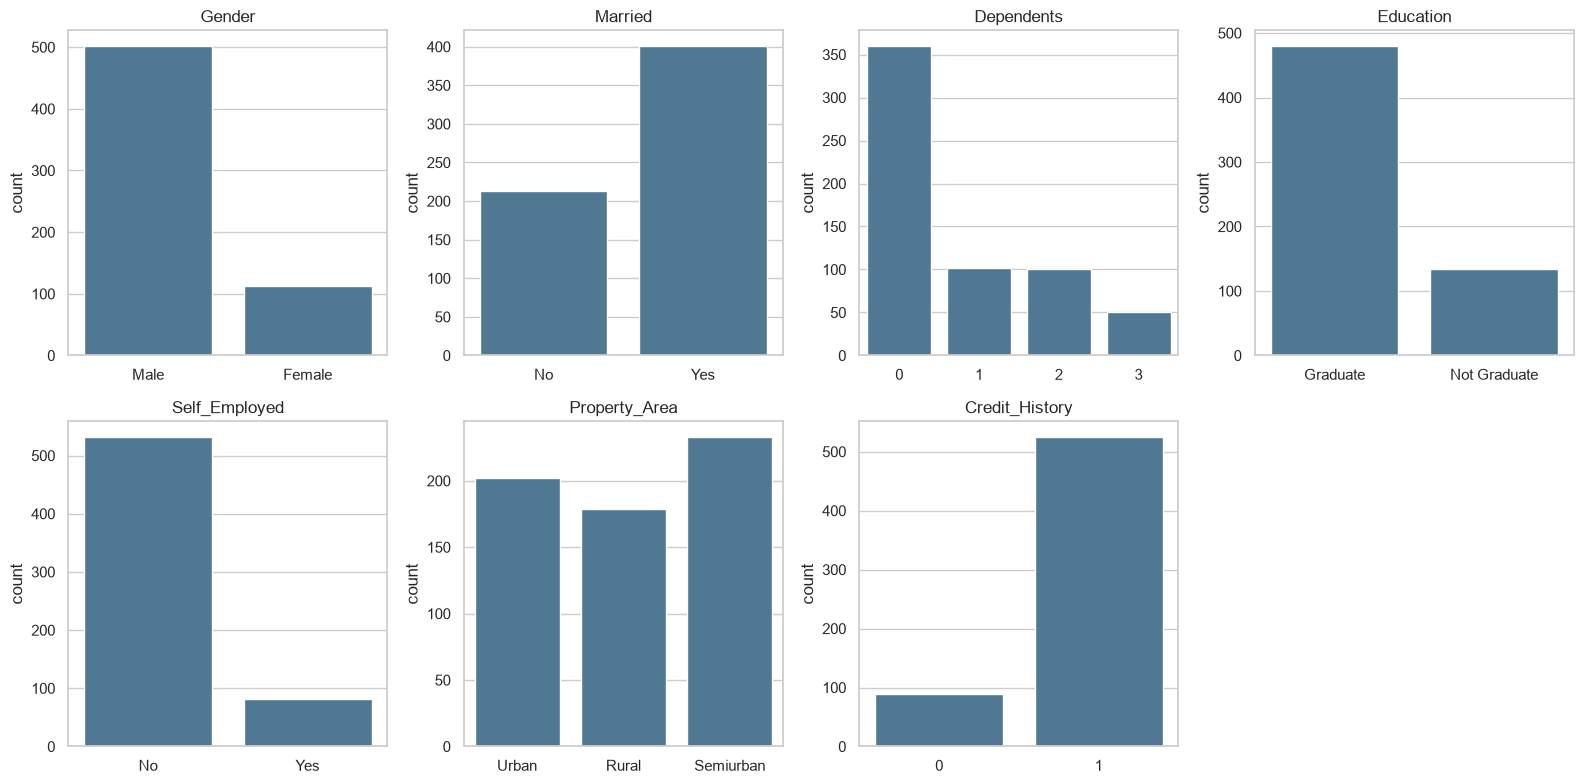

In [16]:
cat_cols = ["Gender", "Married", "Dependents", "Education",
            "Self_Employed", "Property_Area", "Credit_History"]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flat, cat_cols):
    sns.countplot(data=df, x=col, ax=ax, color="#457b9d")
    ax.set_title(col)
    ax.set_xlabel("")
axes.flat[-1].axis("off")   # 7 charts in 8 spaces, so hide the empty one

plt.tight_layout()
plt.savefig("images/02_categories.png", dpi=150, bbox_inches="tight")
plt.show()

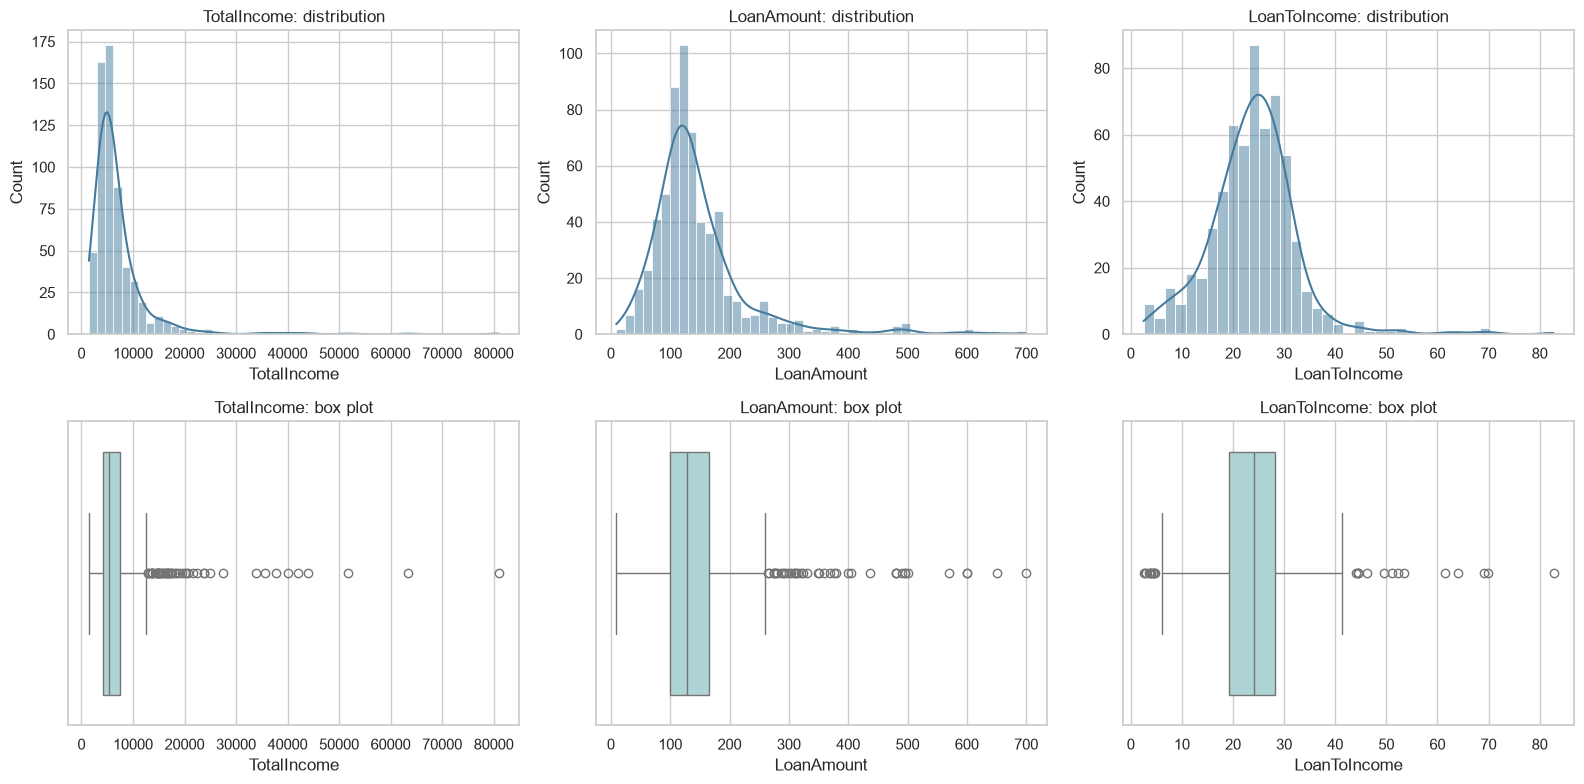

In [17]:
num_cols = ["TotalIncome", "LoanAmount", "LoanToIncome"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[0, i], color="#457b9d")
    axes[0, i].set_title(f"{col}: distribution")
    sns.boxplot(x=df[col], ax=axes[1, i], color="#a8dadc")
    axes[1, i].set_title(f"{col}: box plot")

plt.tight_layout()
plt.savefig("images/03_numeric.png", dpi=150, bbox_inches="tight")
plt.show()

## WHAT DRIVES LOAN APPROVAL?

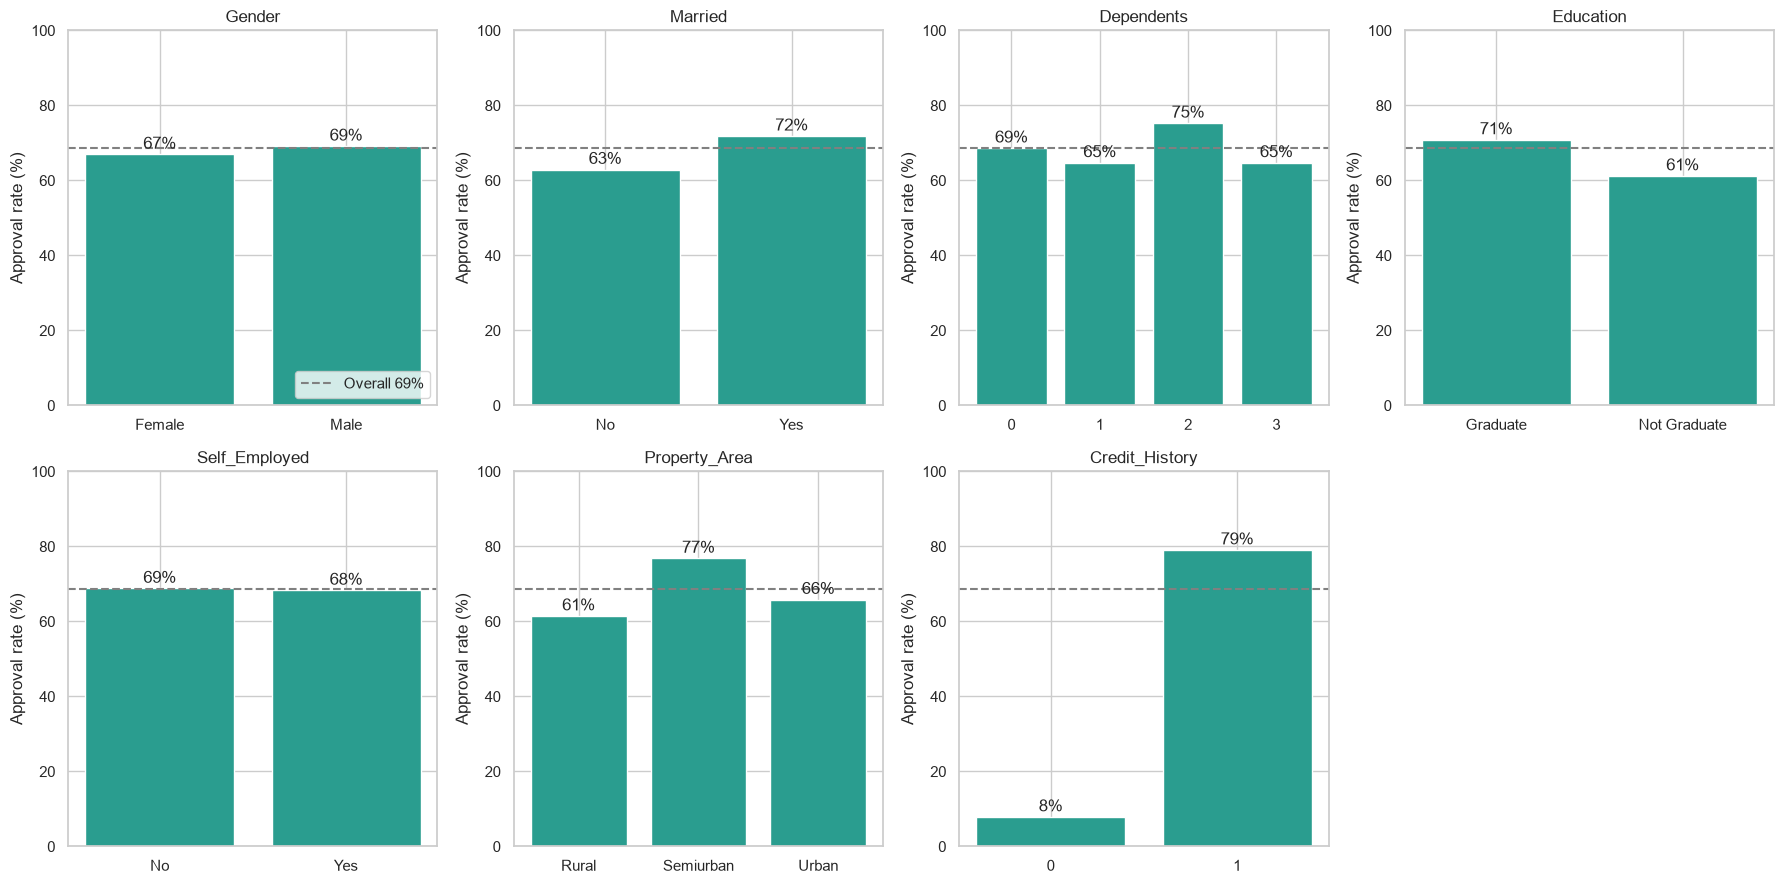

In [18]:
overall = df["Approved"].mean() * 100

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, col in zip(axes.flat, cat_cols):
    rates = df.groupby(col)["Approved"].mean() * 100
    ax.bar(rates.index.astype(str), rates.values, color="#2a9d8f")
    ax.axhline(overall, linestyle="--", color="gray", label=f"Overall {overall:.0f}%")
    for i, v in enumerate(rates.values):
        ax.text(i, v + 1.5, f"{v:.0f}%", ha="center")
    ax.set_title(col)
    ax.set_ylim(0, 100)
    ax.set_ylabel("Approval rate (%)")
axes.flat[0].legend(loc="lower right")
axes.flat[-1].axis("off")

plt.tight_layout()
plt.savefig("images/04_approval_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

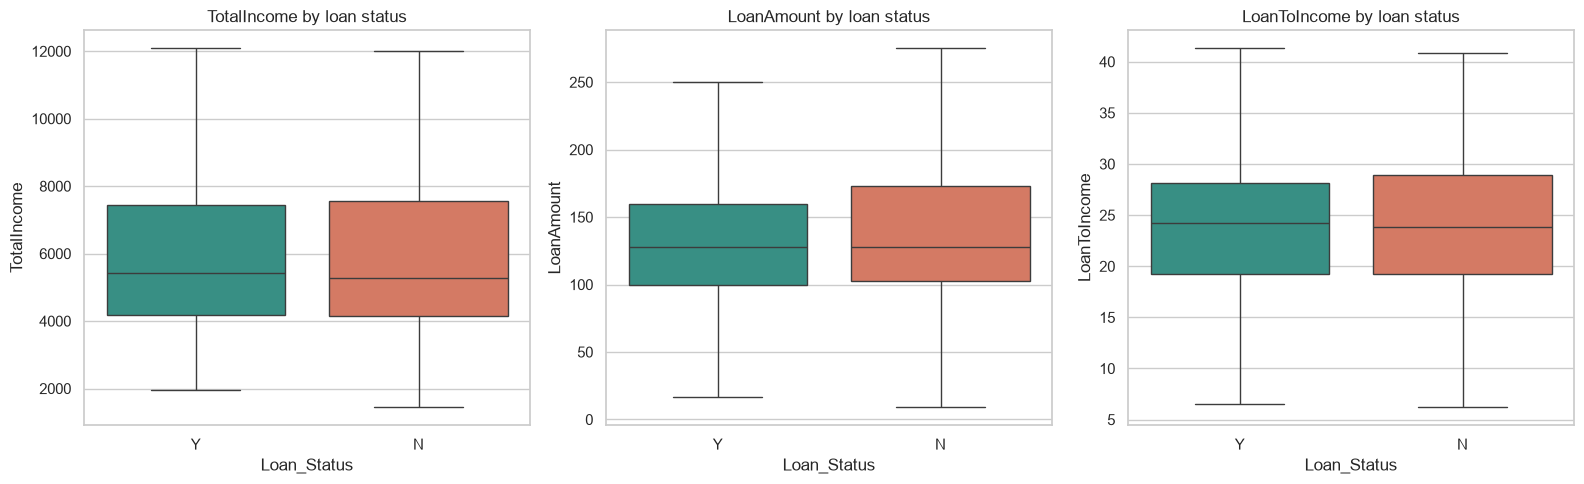

,TotalIncome,LoanAmount,LoanToIncome
Loan_Status,,,
N,5289.5,128.0,23.8
Y,5439.0,128.0,24.2


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x="Loan_Status", y=col, order=["Y", "N"], ax=ax,
                hue="Loan_Status", palette={"Y": "#2a9d8f", "N": "#e76f51"}, legend=False,
                showfliers=False)
    ax.set_title(f"{col} by loan status")

plt.tight_layout()
plt.savefig("images/05_numeric_by_status.png", dpi=150, bbox_inches="tight")
plt.show()

df.groupby("Loan_Status")[num_cols].median()